# GDBN v7: Multi-Day Target (Point-in-Time)

Notebook 08's IC decay showed the GDBN's edge **lasts one day**: holding a stock longer mostly holds noise. Here the GDBN is trained for a **longer horizon** from the start:

- **Target:** each stock's excess return (vs the universe) **summed over the next $h$ days**, for $h$ = 1 (as before), 5 (a week), and 20 (a month).
- **Inputs:** the same as notebook 06 (yesterday's excess return, sentiment, attention, ETFs).
- **Portfolio:** each day, buy the top 20% / short the bottom 20%, and **hold each day's picks for $h$ days** (overlapping portfolios: $1/h$ of the money goes into each day's picks). This trades much less.
- **No look-ahead:** in each quarter's training window, the last $h-1$ days are dropped, so no training target reaches into the quarter being predicted.

**The key comparison:** for $h$ = 5 and 20, is it better to train the model **for** that horizon, or to take the 1-day model and just **hold** it longer?

Same point-in-time universe, walk-forward, λ rule (best rank IC on 2006–2020), and validation (2021–2022) as notebooks 06–08. **Test years are not used.** Takes several minutes.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pit_common as pc
from gdbn_utils import RESULTS

D = pc.load()          # everything after 2022 is blanked out (test years locked)
print(f"{len(D.rebal)} quarters; {len(D.days[D.days <= pc.EVAL_END]):,} trading days up to {pc.EVAL_END}")

H_LIST = [1, 5, 20]

68 quarters; 5,035 trading days up to 2022-12-31


## 1. Walk-forward for each horizon

In [2]:
res = {h: pc.walk_forward(D, pc.daily_features, horizon=h, label=f"target = {h}-day") for h in H_LIST}

  target = 1-day: 20 of 68 quarters
  target = 1-day: 40 of 68 quarters
  target = 1-day: 60 of 68 quarters
  target = 5-day: 20 of 68 quarters
  target = 5-day: 40 of 68 quarters
  target = 5-day: 60 of 68 quarters
  target = 20-day: 20 of 68 quarters
  target = 20-day: 40 of 68 quarters
  target = 20-day: 60 of 68 quarters


## 2. Choose λ for each horizon

For each horizon, the λ with the best average rank IC **against that horizon's return** over 2006–2020.

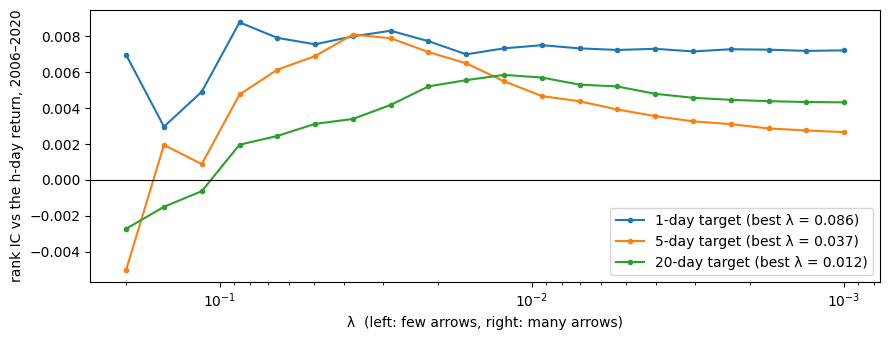

 1-day target: λ = 0.0865, 2006–2020 IC = 0.0088, arrows per quarter ≈ 212
 5-day target: λ = 0.0375, 2006–2020 IC = 0.0081, arrows per quarter ≈ 2259
20-day target: λ = 0.0123, 2006–2020 IC = 0.0059, arrows per quarter ≈ 5317


In [3]:
K, curves = {}, {}
for h in H_LIST:
    K[h], curves[h] = pc.choose_lambda(D, res[h], h)
fig, ax = plt.subplots(figsize=(9, 3.5))
for h in H_LIST:
    ax.semilogx(pc.ALPHAS, curves[h], "o-", ms=3, label=f"{h}-day target (best λ = {pc.ALPHAS[K[h]]:.3f})")
ax.axhline(0, color="black", lw=0.8); ax.invert_xaxis(); ax.legend()
ax.set_xlabel("λ  (left: few arrows, right: many arrows)"); ax.set_ylabel("rank IC vs the h-day return, 2006–2020")
plt.tight_layout(); plt.show()
score = {h: pc.scores(res[h], K[h]) for h in H_LIST}
targets = {h: pc.forward_excess(D, score[1], h) for h in H_LIST}
for h in H_LIST:
    print(f"{h:>2}-day target: λ = {pc.ALPHAS[K[h]]:.4f}, 2006–2020 IC = {curves[h][K[h]]:.4f}, "
          f"arrows per quarter ≈ {np.mean([(q['W'][:, :, K[h]] != 0).sum() for q in res[h]]):.0f}")

## 3. Results

| Row | Model | Held |
|---|---|---|
| 1-day model, held 1 day | notebook 06's setup | 1 day |
| 1-day model, held $h$ days | same model, just held longer | $h$ days |
| **$h$-day model, held $h$ days** | trained for $h$ days | $h$ days |

**IC (vs its horizon):** rank correlation between the score and the return over the holding horizon. Overlapping horizons make returns autocorrelated, so t-statistics use Newey–West with more lags.

In [4]:
def results_table(rows, lags):
    # rows: {name: (score, holding days, IC horizon)}
    out = {}
    for period, (a, b) in pc.PERIODS.items():
        tab = {}
        for name, (score, hold, h_ic) in rows.items():
            s = pc.summary(D, pc.held_weights(score, hold), a, b, lags=max(lags, hold + 5))
            ic = pc.rank_ic(score.loc[a:b], targets[h_ic].loc[a:b])
            s["IC (vs its horizon)"] = ic.mean()
            s["IC t"] = pc.nw_t(ic.values, lags=h_ic + 5)
            tab[name] = s
        out[period] = pd.DataFrame(tab).T
        print(f"===== {period} =====")
        print(out[period][["IC (vs its horizon)", "IC t", "bps/day", "Sharpe gross", "Sharpe net",
                           "turnover/day", "breakeven bps"]].round(3).to_string(), "\n")
    return out

rows = {"1-day model, held 1 day": (score[1], 1, 1)}
for h in [5, 20]:
    rows[f"1-day model, held {h} days"] = (score[1], h, h)
    rows[f"{h}-day model, held {h} days"] = (score[h], h, h)
tables = results_table(rows, lags=5)

===== 2006–2020 walk-forward =====
                            IC (vs its horizon)   IC t  bps/day  Sharpe gross  Sharpe net  turnover/day  breakeven bps
1-day model, held 1 day                   0.009  3.186    2.633         0.472      -1.973         2.724          0.966
1-day model, held 5 days                  0.004  1.493    1.012         0.387      -0.689         0.563          1.798
5-day model, held 5 days                  0.008  1.916    1.085         0.292      -0.481         0.575          1.886
1-day model, held 20 days                 0.003  1.073    0.419         0.298      -0.209         0.143          2.935
20-day model, held 20 days                0.006  0.794    0.287         0.089      -0.133         0.143          2.006 

===== 2021–2022 validation =====
                            IC (vs its horizon)   IC t  bps/day  Sharpe gross  Sharpe net  turnover/day  breakeven bps
1-day model, held 1 day                   0.013  1.480    5.150         0.903      -1.633        

**Reading it:**
- **Turnover** falls roughly by a factor of $h$ when holding $h$ days, so costs fall too.
- **Breakeven bps** (profit per unit traded) is the number to watch: above about 5 bps, the strategy survives realistic costs.
- If the **$h$-day model** beats the **1-day model held $h$ days**, training for the horizon finds relationships that last longer than a day.

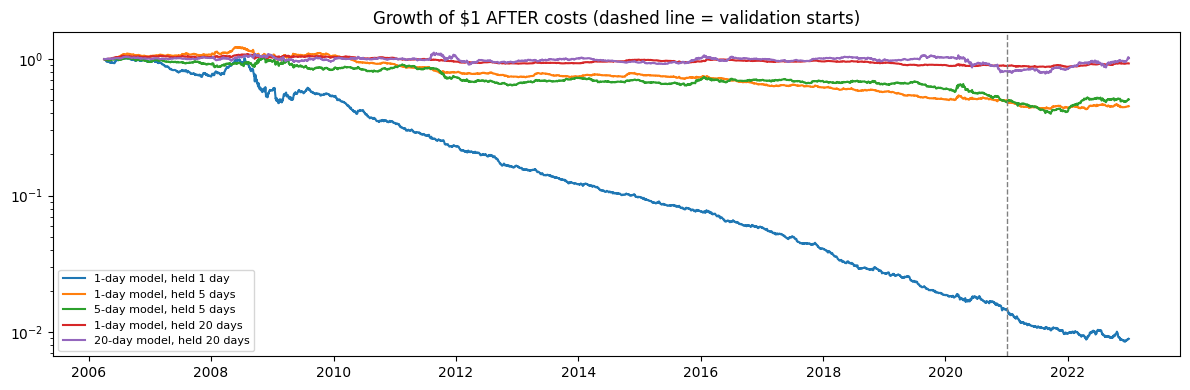

In [5]:
fig, ax = plt.subplots(figsize=(12, 4))
for name, (s, hold, _) in rows.items():
    w = pc.held_weights(s, hold)
    r = D.RET.reindex(index=w.index, columns=w.columns).fillna(0)
    net = (w * r).sum(axis=1) - w.diff().abs().sum(axis=1).fillna(0) * pc.COST_BPS / 1e4
    ax.plot((1 + net.loc[:pc.EVAL_END]).cumprod(), label=name)
ax.axvline(pd.Timestamp("2021-01-01"), color="gray", ls="--", lw=1)
ax.set_yscale("log"); ax.set_title("Growth of $1 AFTER costs (dashed line = validation starts)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Does the multi-day model's signal last longer?

Day-$k$ IC (score vs the return $k$ days later) and ranking stability (score vs the score $k$ days later), 2006–2020.

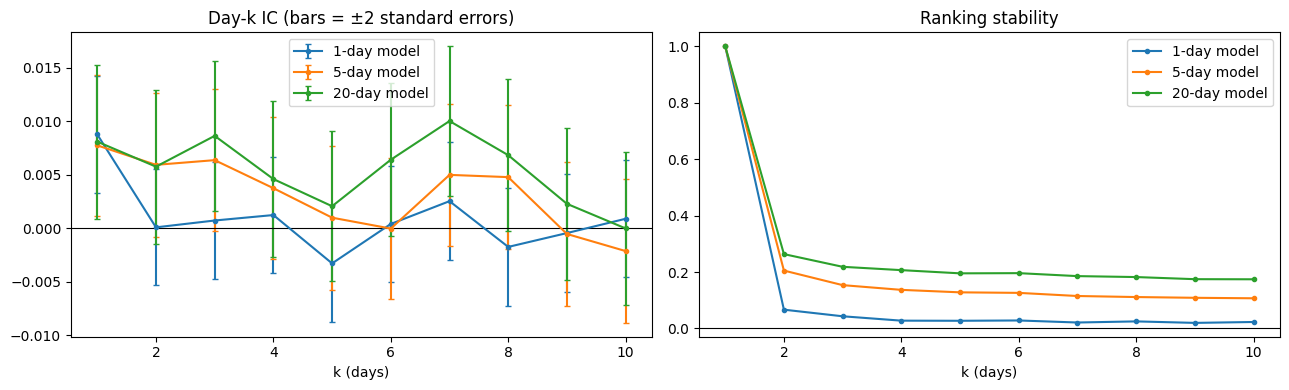

   1-day model                            5-day model                            20-day model                           
      day-k IC day-k SE ranking stability    day-k IC day-k SE ranking stability     day-k IC day-k SE ranking stability
1       0.0088   0.0028            1.0000      0.0078   0.0033            1.0000       0.0081   0.0036            1.0000
2       0.0001   0.0027            0.0667      0.0059   0.0034            0.2052       0.0058   0.0036            0.2635
3       0.0007   0.0028            0.0433      0.0064   0.0033            0.1536       0.0086   0.0035            0.2185
5      -0.0033   0.0027            0.0273      0.0010   0.0034            0.1281       0.0021   0.0035            0.1953
10      0.0009   0.0027            0.0230     -0.0021   0.0034            0.1070      -0.0000   0.0036            0.1743


In [6]:
dec = {h: pc.decay(D, score[h], None, pc.TUNE_END) for h in H_LIST}
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for h in H_LIST:
    d = dec[h]
    axes[0].errorbar(d.index, d["day-k IC"], yerr=2 * d["day-k SE"], marker="o", ms=3, capsize=2, label=f"{h}-day model")
    axes[1].plot(d.index, d["ranking stability"], marker="o", ms=3, label=f"{h}-day model")
axes[0].set_title("Day-k IC (bars = ±2 standard errors)"); axes[1].set_title("Ranking stability")
for ax in axes:
    ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("k (days)"); ax.legend()
plt.tight_layout(); plt.show()
print(pd.concat({f"{h}-day model": dec[h].loc[[1, 2, 3, 5, 10]] for h in H_LIST}, axis=1).round(4).to_string())

## 5. Save results

In [7]:
RESULTS.mkdir(parents=True, exist_ok=True)
pd.concat(tables, names=["period", "model"]).to_csv(RESULTS / "pit_multiday_results.csv")
pd.concat(dec, names=["horizon", "k"]).to_csv(RESULTS / "pit_multiday_decay.csv")
print("Saved to", RESULTS)

Saved to /Users/max_lovinger/Documents/Thesis/CoreFragment/data/results
